<a href="https://colab.research.google.com/github/julestek/nlp-ticket-classification/blob/main/notebooks/02_baseline_tfidf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Repo public :
!git clone https://github.com/julestek/nlp-ticket-classification.git
%cd nlp-ticket-classification

Cloning into 'nlp-ticket-classification'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 30 (delta 10), reused 11 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 161.36 KiB | 17.93 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/nlp-ticket-classification


In [2]:
!head -5 src/preprocessing.py

"""
Preprocessing partagé entre les notebooks d'entraînement et l'API.

Règle d'or : toute transformation appliquée au texte à l'entraînement
doit être appliquée à l'identique à l'inférence. D'où ce module unique.


In [3]:
from google.colab import userdata

!mkdir -p ~/.kaggle
with open('/root/.kaggle/access_token', 'w') as f:
    f.write(userdata.get('KAGGLE_TOKEN'))
!chmod 600 ~/.kaggle/access_token

!pip install -q kaggle
!kaggle datasets download -d adisongoh/it-service-ticket-classification-dataset -p data/raw --unzip

Dataset URL: https://www.kaggle.com/datasets/adisongoh/it-service-ticket-classification-dataset
License(s): CC0-1.0
100% 3.45M/3.45M [00:01<00:00, 2.61MB/s]



In [4]:
import sys
import pandas as pd

sys.path.append('src')
from preprocessing import add_text_columns, make_splits

df = pd.read_csv("data/raw/all_tickets_processed_improved_v3.csv")
df = add_text_columns(df)
train_df, val_df, test_df = make_splits(df)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 33485 | Val: 7176 | Test: 7176


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),   # mots seuls ET paires de mots consécutifs
    min_df=2,             # ignore les termes présents dans moins de 2 tickets
    sublinear_tf=True,    # amortit l'effet des mots très répétés dans un ticket
)

X_train = vectorizer.fit_transform(train_df['text_classical'])
X_val = vectorizer.transform(val_df['text_classical'])

y_train = train_df['Topic_group']
y_val = val_df['Topic_group']

print(f"X_train : {X_train.shape}")
print(f"X_val   : {X_val.shape}")
density = X_train.nnz / (X_train.shape[0] * X_train.shape[1]) * 100
print(f"Densité : {density:.3f}% de valeurs non nulles")

X_train : (33485, 113892)
X_val   : (7176, 113892)
Densité : 0.036% de valeurs non nulles


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_val)

print(f"Accuracy : {accuracy_score(y_val, y_pred):.4f}")
print(f"F1-macro : {f1_score(y_val, y_pred, average='macro'):.4f}")
print()
print(classification_report(y_val, y_pred, digits=3))

Accuracy : 0.8467
F1-macro : 0.8462

                       precision    recall  f1-score   support

               Access      0.927     0.866     0.896      1069
Administrative rights      0.911     0.617     0.736       264
           HR Support      0.847     0.852     0.849      1637
             Hardware      0.767     0.897     0.827      2043
     Internal Project      0.942     0.764     0.844       318
        Miscellaneous      0.837     0.818     0.827      1059
             Purchase      0.985     0.862     0.919       369
              Storage      0.957     0.801     0.872       417

             accuracy                          0.847      7176
            macro avg      0.897     0.810     0.846      7176
         weighted avg      0.855     0.847     0.847      7176



In [7]:
results = {}
results['tfidf_logreg_sans_poids'] = f1_score(y_val, y_pred, average='macro')

clf_w = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
clf_w.fit(X_train, y_train)
y_pred_w = clf_w.predict(X_val)

results['tfidf_logreg_avec_poids'] = f1_score(y_val, y_pred_w, average='macro')

print(f"Accuracy : {accuracy_score(y_val, y_pred_w):.4f}")
print(f"F1-macro : {results['tfidf_logreg_avec_poids']:.4f}")
print()
print(classification_report(y_val, y_pred_w, digits=3))

Accuracy : 0.8542
F1-macro : 0.8592

                       precision    recall  f1-score   support

               Access      0.899     0.890     0.894      1069
Administrative rights      0.690     0.867     0.768       264
           HR Support      0.889     0.828     0.857      1637
             Hardware      0.854     0.811     0.832      2043
     Internal Project      0.819     0.925     0.869       318
        Miscellaneous      0.795     0.867     0.829      1059
             Purchase      0.941     0.908     0.924       369
              Storage      0.867     0.935     0.900       417

             accuracy                          0.854      7176
            macro avg      0.844     0.879     0.859      7176
         weighted avg      0.857     0.854     0.855      7176



In [8]:
import numpy as np

feature_names = np.array(vectorizer.get_feature_names_out())

for i, cls in enumerate(clf_w.classes_):
    top_idx = np.argsort(clf_w.coef_[i])[-10:][::-1]
    print(f"{cls:22s} → {', '.join(feature_names[top_idx])}")
    print()

Access                 → confluence, user, card, license, account, password, git, repository, accounts, users

Administrative rights  → outlook, upgrade, issues, install, windows, software, update, version, exchange, problem

HR Support             → access, error, starter, oracle, leave, time, submit, leaver, new starter, timecard

Hardware               → laptop, monitor, room, phone, connection, meeting, cable, connect, call, backpack

Internal Project       → code, project, codes, pipeline, setup, pas, import, unknown, opportunity, pipelines

Miscellaneous          → change, add, approval, approve, ticket, groups, tickets, name, owner, approver

Purchase               → po, purchase, installation, administrator, log, device, administrator phone, items, allocation, devices

Storage                → folder, mailbox, wants, storage, shared, folders, permissions, files, increase, archive



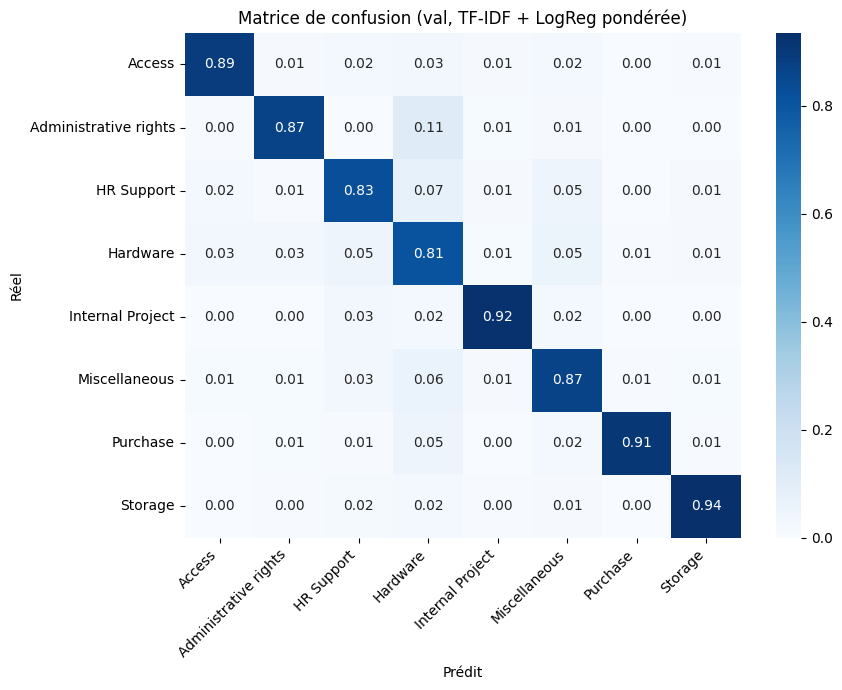

                       Access  Administrative rights  HR Support  Hardware  \
Access                   0.89                   0.01        0.02      0.03   
Administrative rights    0.00                   0.87        0.00      0.11   
HR Support               0.02                   0.01        0.83      0.07   
Hardware                 0.03                   0.03        0.05      0.81   
Internal Project         0.00                   0.00        0.03      0.02   
Miscellaneous            0.01                   0.01        0.03      0.06   
Purchase                 0.00                   0.01        0.01      0.05   
Storage                  0.00                   0.00        0.02      0.02   

                       Internal Project  Miscellaneous  Purchase  Storage  
Access                             0.01           0.02      0.00     0.01  
Administrative rights              0.01           0.01      0.00     0.00  
HR Support                         0.01           0.05      0.00     

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = sorted(y_val.unique())
cm = confusion_matrix(y_val, y_pred_w, labels=labels, normalize='true')

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.title('Matrice de confusion (val, TF-IDF + LogReg pondérée)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(pd.DataFrame(cm, index=labels, columns=labels).round(2))

In [10]:
mask = train_df['text_classical'].str.contains(r'\bpas\b')
print(f"Tickets contenant 'pas' : {mask.sum()}")
print(train_df[mask]['Topic_group'].value_counts())
print()
print(train_df[mask]['Document'].iloc[0][:300])

Tickets contenant 'pas' : 978
Topic_group
Internal Project         473
HR Support               250
Hardware                 116
Miscellaneous             95
Access                    17
Storage                   14
Administrative rights      9
Purchase                   4
Name: count, dtype: int64

access to new pas november pm dear please visualize generate reports had type old right matter urgency thank head


## Palier 1 : TF-IDF + régression logistique (état d'avancement)

**Configuration** : TfidfVectorizer (ngram 1-2, min_df=2, sublinear_tf) sur `text_classical`,
113 892 features, fit sur le train uniquement. LogisticRegression, C=1 (défaut, non réglé).

| Variante | Accuracy (val) | F1-macro (val) |
|---|---|---|
| Sans pondération | 0.847 | 0.846 |
| class_weight='balanced' | 0.854 | 0.859 |

**Observations**
- La pondération inverse le compromis : precision > recall sans poids, recall > precision avec.
- Administrative rights : recall 0.617 → 0.867, mais precision 0.911 → 0.690.
- Hardware agit comme classe « aimant » : première source d'erreurs de presque toutes les autres classes.
- Confusion principale : Administrative rights → Hardware (11 %).
- Coefficients : vocabulaire métier dominant, pas d'artefacts évidents (noms, sociétés) dans les top mots.
  Le token « pas » (système interne ?) pèse sur Internal Project, à examiner en Phase 4.
- Réserve : écarts de 1-2 points non interprétables sur les petites classes (264 à 418 exemples en val).

**À faire** : régler C (grille 0.1 à 100) pour les deux variantes avant de comparer aux paliers 2 et 3.
Le test set n'a pas encore été utilisé.